> **Trainierte Modelle:** Dieses Notebook lädt das fertige Modell aus `models/` und trainiert nicht neu. Zum Neutrainieren in den Parametern `TRAIN_MODEL = True` setzen.

## 📝 Hinweise: Umbau dieses Autoencoders zu einem Variational Autoencoder (VAE)

Die folgenden Zellen wurden (minimal) gegenüber dem einfachen Autoencoder angepasst, sodass das Modell zu einem **Variational Autoencoder** wird. Ein VAE unterscheidet sich von einem einfachen AE dadurch, dass der Encoder eine *Wahrscheinlichkeitsverteilung* über dem latenten Raum ausgibt statt eines einzelnen festen Punkts. Das regularisiert den latenten Raum (er wird kontinuierlich und um eine Standardnormalverteilung zentriert), sodass später daraus gesampelt werden kann, um neue, nie gesehene Bilder zu erzeugen und nicht nur vorhandene zu rekonstruieren.

**Was sich geändert hat und warum:**

1. **Imports** (Zelle `Preparation`): `keras`, `tensorflow as tf` sowie `losses`, `optimizers`, `metrics` aus `tensorflow.keras` ergänzt; sie werden für den eigenen Loss- und Trainingscode unten gebraucht.
2. **Parameter**: `BETA = 500` ergänzt, ein Gewicht für den Rekonstruktions-Loss relativ zum KL-Divergenz-Loss (siehe Punkt 6). Es ist derselbe Wert wie im Fashion-MNIST-Referenznotebook für den VAE (`vae.ipynb`) in diesem Ordner.
3. **`Sampling`-Layer** (neue Zelle vor dem Encoder): implementiert den *Reparametrisierungstrick* `z = z_mean + exp(0.5 * z_log_var) * epsilon`. Dadurch können Gradienten durch den sonst nicht differenzierbaren Zufallsschritt fließen, weil der Zufall in einen externen Input `epsilon ~ N(0, 1)` verlagert wird.
4. **Encoder**: Statt eines einzelnen `Dense(EMBEDDING_DIM)`, das ein deterministisches Embedding erzeugt, hat der Encoder jetzt zwei Ausgabeköpfe, `z_mean` und `z_log_var` (Mittelwert und Log-Varianz einer Gaußverteilung), sowie einen gesampelten latenten Vektor `z = Sampling()([z_mean, z_log_var])`. Das `Model` des Encoders gibt jetzt `[z_mean, z_log_var, z]` zurück. Der konvolutionale Teil zur Merkmalsextraktion (Conv2D-Stapel) ist **unverändert**.
5. **Decoder**: **vollständig unverändert.** Seine Aufgabe (latenter Vektor → 32×32×3-Bild) bleibt gleich, egal ob der latente Vektor aus einem einfachen `Dense`-Layer oder aus dem Sampling stammt. Geändert hat sich nur die *Quelle* des latenten Vektors, nicht der Decoder selbst.
6. **`VAE`-Modellklasse** (neue Zelle nach dem Decoder): ersetzt das einzelne `models.Model(encoder_input, decoder(encoder_output))`. Ein eigener `train_step`/`test_step` ist nötig, weil der VAE-Loss **kein** einfacher eingebauter Keras-Loss ist. Er ist die Summe aus:
   - einem **Rekonstruktions-Loss** (binäre Kreuzentropie zwischen Eingabe und Rekonstruktion, skaliert mit `BETA`) und
   - einem **KL-Divergenz-Loss** `-0.5 * sum(1 + z_log_var - z_mean² - exp(z_log_var))`, der die latente Verteilung jedes Bildes zu einer Standardnormalverteilung `N(0, I)` hinzieht. Das gibt dem latenten Raum seine glatte, kontinuierliche, für die Generierung geeignete Struktur.

   Keras hat für diese Kombination keinen eingebauten `loss=`-String, sodass `compile()`/`fit()` sie nicht direkt ausdrücken können. Der eigene `train_step` berechnet beide Terme, summiert sie und wendet die Gradienten manuell an.
7. **Compile-Schritt**: kein `loss="binary_crossentropy"` mehr (der Loss liegt jetzt in `train_step`). Umgestellt auf `optimizers.Adam(learning_rate=0.0005)`, niedriger als Adams Standardwert `0.001`, für stabileres Training, da nun zwei Loss-Terme auszubalancieren sind.
8. **`fit()`-Aufruf**: jetzt `vae.fit(x_train, ...)` **ohne** zweites `x_train`-Zielargument. `train_step` erhält einen Bild-Batch und rekonstruiert ihn intern über `self(data)`, statt dass Keras eine Vorhersage mit einem expliziten `y` vergleicht.
9. **Rekonstruktions- und Embedding-Zellen**: `vae.predict(...)` und `encoder.predict(...)` geben jetzt jeweils ein 3-Tupel `(z_mean, z_log_var, reconstruction_or_z)` statt eines einzelnen Arrays zurück, deshalb wurde das Entpacken ergänzt (`_, _, predictions = vae.predict(...)` und `z_mean, z_log_var, embeddings = encoder.predict(...)`). Alles Nachfolgende (die `display(...)`-Aufrufe, die Streudiagramme von `embeddings`) ist unverändert.

**Zwei Fehler, die beim Smoke-Test dieses Umbaus gefunden und behoben wurden (nicht im einfachen AE vorhanden; beide treten erst auf, wenn `vae.fit(...)` tatsächlich eine ganze Epoche durchläuft):**

10. **`VAE.get_config()` / `from_config()`** (in der Klasse `VAE`): Die installierte Keras-Version verlangt, dass jedes abgeleitete `Model`, dessen `__init__` nicht serialisierbare Argumente erhält (hier die Modelle `encoder`/`decoder`), `get_config`/`from_config` implementiert. Ohne das löste der *erste* Serialisierungsversuch, ausgelöst durch `ModelCheckpoint` am Ende von Epoche 1 und später durch `vae.save(...)`, `NotImplementedError: ... must override get_config()` aus. Behoben durch Serialisieren und Deserialisieren von `encoder`/`decoder` über `keras.saving.serialize_keras_object` / `deserialize_keras_object`.
11. **`ModelCheckpoint(monitor=...)`** (in der Checkpoint-Zelle): stand noch auf `monitor="loss"`, aber der eigene `train_step` des VAE meldet nur `total_loss`, `reconstruction_loss` und `kl_loss` (siehe `VAE.metrics`); einen einfachen Schlüssel `"loss"` gibt es nicht. Mit `"loss"` warnt der Callback nur in jeder Epoche `"Can save best model only with loss available"` und speichert nie einen Checkpoint. Geändert zu `monitor="total_loss"`.

**Nicht geändert / außerhalb des Umfangs:** Die Abschnitte „neue Bilder durch Sampling zufälliger Punkte im latenten Raum erzeugen“ und „den latenten Raum über die Normalverteilungsfunktion erkunden“ aus der Referenz `vae.ipynb` wurden hier bewusst **nicht** ergänzt, damit diese Änderung klein bleibt und sich auf den Umbau des Modells selbst konzentriert. Sie könnten später nach demselben Muster wie in `vae.ipynb` in diesem Ordner ergänzt werden.

# Autoencoder auf CIFAR-10

## Aufgabenbeschreibung

Wir haben gesehen, wie man einen Autoencoder für die Graustufenbilder des Fashion-MNIST-Datensatzes baut. In dieser Übung baust du einen für den CIFAR-10-Datensatz (https://www.cs.toronto.edu/~kriz/cifar.html). Dieser Datensatz enthält **Farbbilder** mit einer Auflösung von 32x32.

### Vorbereitung


In [1]:
import matplotlib.pyplot as plt


def sample_batch(dataset):
    batch = dataset.take(1).get_single_element()
    if isinstance(batch, tuple):
        batch = batch[0]
    return batch.numpy()


def display(
    images, n=10, size=(20, 3), cmap="gray_r", as_type="float32", save_to=None
):
    """
    Zeigt n Bilder aus jedem der übergebenen Arrays an.
    """
    if images.max() > 1.0:
        images = images / 255.0
    elif images.min() < 0.0:
        images = (images + 1.0) / 2.0

    plt.figure(figsize=size)
    for i in range(n):
        _ = plt.subplot(1, n, i + 1)
        plt.imshow(images[i].astype(as_type), cmap=cmap)
        plt.axis("off")

    if save_to:
        plt.savefig(save_to)
        print(f"\nSaved to {save_to}")

    plt.show()



In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import keras
import tensorflow as tf
from tensorflow.keras import layers, models, datasets, callbacks, losses, optimizers, metrics
import tensorflow.keras.backend as K


I0000 00:00:1793543064.594205 2015597 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793543065.676034 2015597 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 0. Parameter <a name="parameters"></a>

In [3]:
IMAGE_SIZE = 32
CHANNELS = 3
BATCH_SIZE = 100
BUFFER_SIZE = 1000
VALIDATION_SPLIT = 0.2
EMBEDDING_DIM = 2
EPOCHS = 5
BETA = 500  # VAE-Ergänzung: Gewicht des Rekonstruktions-Loss relativ zum KL-Loss [Gewicht: festgelegt]

# Eigene Modelle laden statt neu trainieren. True trainiert neu.
TRAIN_MODEL = False

## 1. Daten vorbereiten <a name="prepare"></a>

In [4]:
# Daten laden
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

In [5]:
# Daten vorverarbeiten

def preprocess(imgs):
    """
    Normalisiert die Bilder und bringt sie in die richtige Form
    """
    imgs = imgs.astype("float32") / 255.0
    imgs = imgs.reshape(len(imgs),imgs.shape[1],imgs.shape[2],3)
    return imgs


x_train = preprocess(x_train)
x_test = preprocess(x_test)

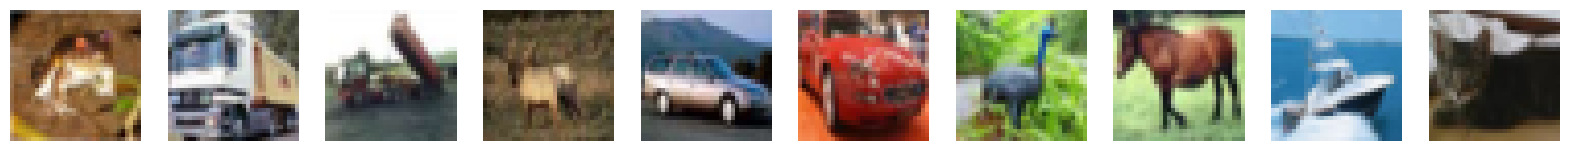

In [6]:
# Einige Bilder aus dem Trainingsset anzeigen
display(x_train)

## 2. Variational Autoencoder aufbauen <a name="build"></a>

In [7]:
# VAE-Ergänzung: Reparametrisierungstrick als Keras-Layer, damit das Sampling
# von z aus (z_mean, z_log_var) für Backprop differenzierbar bleibt.
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = K.random_normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

In [8]:
# Encoder
encoder_input = layers.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS), name="encoder_input"
)
x = layers.Conv2D(32, (3, 3), strides=2, activation="relu", padding="same")(
    encoder_input
)
x = layers.Conv2D(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2D(128, (3, 3), strides=2, activation="relu", padding="same")(x)
shape_before_flattening = K.int_shape(x)[1:]  # wird vom Decoder gebraucht!

x = layers.Flatten()(x)
# VAE-Änderung: zwei Ausgabeköpfe (Mittelwert + Log-Varianz einer Gaußverteilung)
# statt eines deterministischen Embeddings, dazu ein über den Sampling-Layer oben
# gesampeltes z.
z_mean = layers.Dense(EMBEDDING_DIM, name="z_mean")(x)
z_log_var = layers.Dense(EMBEDDING_DIM, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

encoder = models.Model(encoder_input, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 16, 16,    │        896 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 8, 8, 64)  │     18,496 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 4, 4, 128) │     73,856 │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 2048)      │          0 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │      4,098 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │      4,098 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 101,444 (396.27 KB)

 Trainable params: 101,444 (396.27 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Decoder
decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
x = layers.Dense(int(np.prod(shape_before_flattening)))(decoder_input)
x = layers.Reshape(shape_before_flattening)(x)
x = layers.Conv2DTranspose(
    128, (3, 3), strides=2, activation="relu", padding="same"
)(x)
x = layers.Conv2DTranspose(
    64, (3, 3), strides=2, activation="relu", padding="same"
)(x)
x = layers.Conv2DTranspose(
    32, (3, 3), strides=2, activation="relu", padding="same"
)(x)
decoder_output = layers.Conv2D(
    CHANNELS,
    (3, 3),
    strides=1,
    activation="sigmoid",
    padding="same",
    name="decoder_output",
)(x)

decoder = models.Model(decoder_input, decoder_output)
decoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 246,851 (964.26 KB)

 Trainable params: 246,851 (964.26 KB)

 Non-trainable params: 0 (0.00 B)

### Gewichtung der Note: wo festgelegt, wo verwendet

Im Code sind die Stellen mit `[Gewicht]` markiert.

| Gewicht | Wert | Festgelegt | So ermittelt | Verwendet |
|---|---|---|---|---|
| `BETA` (Pixelvergleich gegen KL) | 500 | Abschnitt 0, Parameter | Nicht ermittelt: derselbe Wert wie im Kursbeispiel `vae.ipynb`. Keine Testreihe, kein Annealing, der Wert bleibt im ganzen Training gleich | `train_step` direkt unter diesem Text, in `reconstruction_loss` |

`reconstruction_loss` ist BETA × BCE (Durchschnitt über alle Pixel). `kl_loss` wird über die 2 Code-Zahlen summiert und über den Stapel gemittelt. `total_loss` addiert beide.

**Anteile laut Trainingslog:** BCE 99,3 % und KL 0,7 % im ersten Durchgang, 99,0 % und 1,0 % im fünften. Die KL-Strafe zählt also kaum.

In [10]:
# VAE-Ergänzung: Eine eigene Model-Unterklasse ist nötig, weil der VAE-Loss
# (Rekonstruktion + KL-Divergenz) im Training z_mean/z_log_var braucht, was ein
# einfaches compile(loss=...) nicht ausdrücken kann.
class VAE(models.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = metrics.Mean(name="kl_loss")

    def get_config(self):
        # Korrektur: Diese Keras-Version verlangt get_config/from_config für jedes
        # abgeleitete Model, dessen __init__ nicht serialisierbare Argumente erhält
        # (hier die Keras-Modelle encoder/decoder). Ohne das lösen
        # vae.fit(..., callbacks=[ModelCheckpoint(...)]) und vae.save(...)
        # "NotImplementedError: ... must override get_config()" aus.
        base_config = super().get_config()
        config = {
            "encoder": keras.saving.serialize_keras_object(self.encoder),
            "decoder": keras.saving.serialize_keras_object(self.decoder),
        }
        return {**base_config, **config}

    @classmethod
    def from_config(cls, config):
        encoder = keras.saving.deserialize_keras_object(config.pop("encoder"))
        decoder = keras.saving.deserialize_keras_object(config.pop("decoder"))
        return cls(encoder, decoder, **config)

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        reconstruction = self.decoder(z)
        return z_mean, z_log_var, reconstruction

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, reconstruction = self(data)
            reconstruction_loss = tf.reduce_mean(
                BETA
                * losses.binary_crossentropy(
                    data, reconstruction, axis=(1, 2, 3)
                )
            )
            kl_loss = tf.reduce_mean(
                tf.reduce_sum(
                    -0.5
                    * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)),
                    axis=1,
                )
            )
            # [Gewicht: verwendet] BETA steckt in reconstruction_loss, hier entsteht die Summe.
            total_loss = reconstruction_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        z_mean, z_log_var, reconstruction = self(data)
        reconstruction_loss = tf.reduce_mean(
            BETA
            * losses.binary_crossentropy(data, reconstruction, axis=(1, 2, 3))
        )
        kl_loss = tf.reduce_mean(
            tf.reduce_sum(
                -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)),
                axis=1,
            )
        )
        total_loss = reconstruction_loss + kl_loss

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss,
        }

In [11]:
# VAE-Ergänzung: Encoder und Decoder in das eigene VAE-Modell packen, statt sie
# mit einem einfachen funktionalen Model zu verbinden.
vae = VAE(encoder, decoder)

## 3. Variational Autoencoder trainieren <a name="train"></a>

In [12]:
# Variational Autoencoder kompilieren
# VAE-Änderung: kein loss= hier, der Loss wird in VAE.train_step / test_step
# berechnet. Niedrigere Lernrate als Adams Standardwert für mehr Stabilität, da der
# Loss jetzt zwei konkurrierende Terme hat (Rekonstruktion + KL).
optimizer = optimizers.Adam(learning_rate=0.0005)
vae.compile(optimizer=optimizer)

In [13]:
# Checkpoint zum Speichern des Modells anlegen
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="./checkpoint.keras",
    save_weights_only=False,
    save_freq="epoch",
    # VAE-Änderung: Der eigene train_step des VAE meldet "total_loss" (siehe die
    # Property VAE.metrics oben), nicht "loss". monitor muss diesem Namen entsprechen,
    # sonst warnt ModelCheckpoint nur "Can save best model only with loss available"
    # und speichert nie.
    monitor="total_loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs")

In [14]:
if TRAIN_MODEL:
    # VAE-Änderung: kein explizites Ziel (x_train, x_train). train_step erhält einen
    # Bild-Batch und rekonstruiert ihn intern über self(data).
    vae.fit(
        x_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        validation_data=(x_test, x_test),
        callbacks=[model_checkpoint_callback, tensorboard_callback],
    )
else:
    encoder.set_weights(models.load_model("./models/encoder_v2.keras", compile=False, custom_objects={"Sampling": Sampling}, safe_mode=False).get_weights())
    decoder.set_weights(models.load_model("./models/decoder_v2.keras", compile=False, custom_objects={"Sampling": Sampling}, safe_mode=False).get_weights())

In [15]:
if TRAIN_MODEL:
    # Finale Modelle speichern
    from pathlib import Path
    Path("./models").mkdir(parents=True, exist_ok=True)
    vae.save("./models/vae_v2.keras")
    encoder.save("./models/encoder_v2.keras")
    decoder.save("./models/decoder_v2.keras")

## 4. Rekonstruieren mit dem Variational Autoencoder <a name="reconstruct"></a>

In [16]:
n_to_predict = 5000
example_images = x_test[:n_to_predict]
example_labels = y_test[:n_to_predict]

  1/157 ━━━━━━━━━━━━━━━━━━━━ 19s 125ms/step

 12/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step   

 22/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 32/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 41/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 50/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

... (12 outputs left out)

153/157 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


Example real images


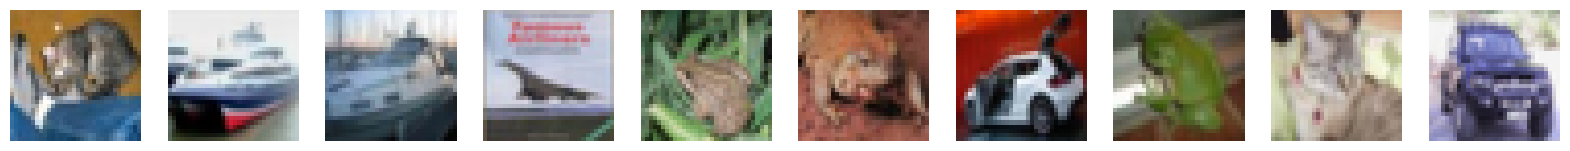

Reconstructions


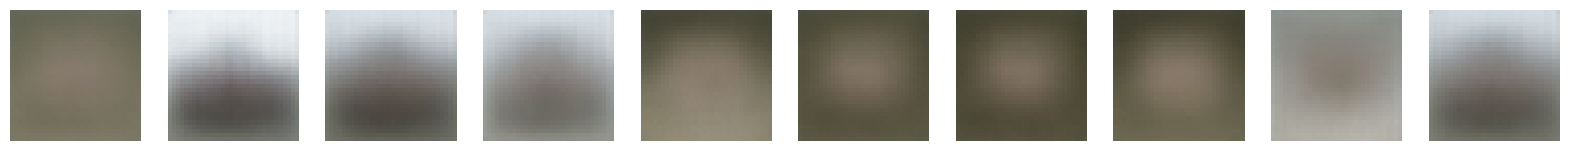

In [17]:
# VAE-Änderung: vae.predict(...) gibt (z_mean, z_log_var, reconstruction) statt
# eines einzelnen Tensors zurück; hier wird nur die Rekonstruktion gebraucht.
_, _, predictions = vae.predict(example_images)

print("Example real images")
display(example_images)
print("Reconstructions")
display(predictions)

## 5. Einbetten mit dem Encoder <a name="encode"></a>

In [18]:
# Beispielbilder kodieren
# VAE-Änderung: encoder.predict(...) gibt jetzt (z_mean, z_log_var, z) zurück;
# z übernimmt dieselbe Rolle wie "embeddings" beim einfachen Autoencoder.
z_mean, z_log_var, embeddings = encoder.predict(example_images)

  1/157 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step

 40/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

 78/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

114/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

151/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [19]:
# Einige Beispiele der Embeddings
print(embeddings[:10])

[[-0.01089413 -0.64647996]
 [ 1.0849541   1.8374405 ]
 [ 1.064343    1.041764  ]
 [ 0.47932458  0.96080077]
 [ 0.07475388 -1.0470273 ]
 [ 0.17558834 -0.6223827 ]
 [ 0.41477168 -1.4700664 ]
 [-0.08161521 -0.9083997 ]
 [-1.1854665   0.60396665]
 [ 0.4606231   1.0885265 ]]


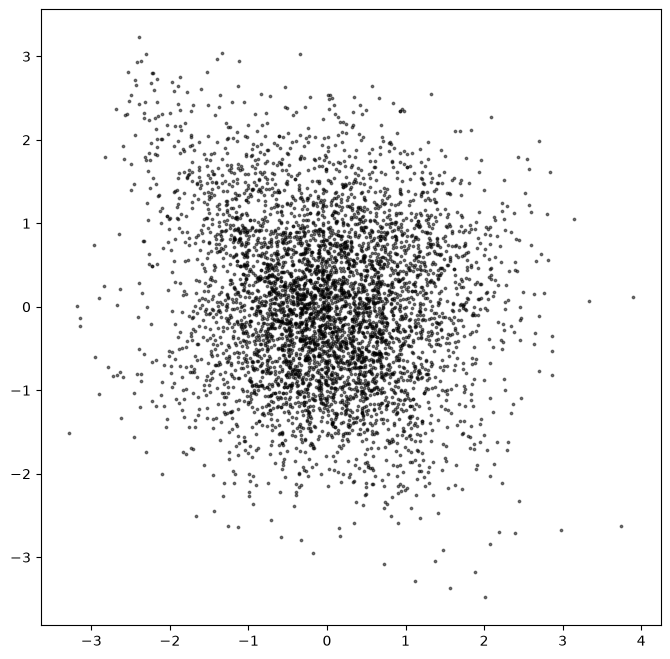

In [20]:
# Die kodierten Punkte im 2D-Raum anzeigen
figsize = 8

plt.figure(figsize=(figsize, figsize))
plt.scatter(embeddings[:, 0], embeddings[:, 1], c="black", alpha=0.5, s=3)
plt.show()

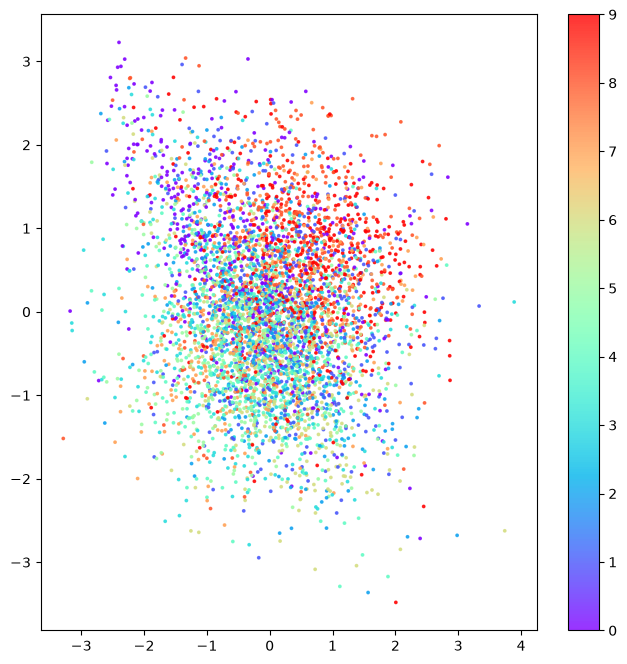

In [21]:
# Embeddings nach ihrem Label einfärben
example_labels = y_test[:n_to_predict]

figsize = 8
plt.figure(figsize=(figsize, figsize))
plt.scatter(
    embeddings[:, 0],
    embeddings[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar()
plt.show()